# Two Moons: uncertainty attribution with probly and shapiq

This notebook trains a deep ensemble and an MC Dropout model on the two moons dataset and uses probly to split their predictive uncertainty into aleatoric and epistemic parts.
It then uses shapiq to attribute these uncertainties to the two input features with Shapley values, comparing two ways of handling unknown features.

1. Setup: versions and imports
2. Deep Ensemble: train three members and plot their uncertainty
3. API check: inspect `quantify` and verify it by hand
4. MC Dropout: the same pipeline with a dropout model
5. Variations: more noise, fewer points, more members, selected points
6. Attribution with shapiq: game definition, both orders, interaction, model comparison

## Step 1: Setup

Check package versions and import what the notebook needs, including `shapiq` for Step 6.

In [ ]:
from importlib.metadata import version

import probly
import shapiq
import sklearn

# Log versions so that results can be traced back to an environment
print("probly", version("probly"))
print("shapiq", version("shapiq"))
print("sklearn", version("scikit-learn"))

c:\dev\probly
probly 0.9.2.dev72+g1189b3aef.d20261106
shapiq 1.8.0
sklearn 1.8.0


In [ ]:
import sys
from pathlib import Path

# Find the repo root (folder with pyproject.toml) so that `examples.utils` can be imported
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(repo_root))
print(repo_root)

import torch
from sklearn.datasets import make_moons
from torch import nn

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty
from probly.representer import representer
from probly.transformation import ensemble

c:\dev\probly


## Step 2: Deep Ensemble

### 2a: Data

Generate the two moons dataset as NumPy arrays.

In [5]:
# Two interleaved half circles; low noise keeps the classes separated, random_state fixes the data
X, y = make_moons(n_samples=500, noise=0.05, random_state=0)

### 2b: Tensors

Convert the data to PyTorch tensors for training.

In [ ]:
# Model weights are float32 and cross_entropy expects class indices as int64
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).long()

### 2c: Base model

Create the MLP that serves as the template for all ensemble members.

In [6]:
# Template only: 2 inputs, two hidden layers of 64 units, 2 output logits; just its copies get trained in 2e
base_model = MLPClassifier()

### 2d: Ensemble

Turn the base model into three independently initialized members.

In [ ]:
# Returns an nn.ModuleList of copies, so the members can be iterated over and trained one by one
ensemble_model = ensemble(
    base_model,
    num_members=3,
    reset_params=True,  # fresh init per member maximizes diversity
    predictor_type="logit_classifier",  # tells probly that outputs are logits of a categorical distribution
)

### 2e: Training

Train each member separately on the full dataset with Adam.

In [7]:
ensemble_model.train()  # standard before training; this MLP has no dropout or batch norm, so it changes nothing here
for member in ensemble_model:
    # One optimizer per member; same data and full batches, so diversity comes only from the different inits
    opt = torch.optim.Adam(member.parameters(), lr=1e-3)
    for epoch in range(250):
        opt.zero_grad()  # clear the gradients of the previous step
        out = member(X_tensor)
        loss = nn.functional.cross_entropy(out, y_tensor)  # takes raw logits, applies log-softmax internally
        loss.backward()
        opt.step()

### 2f: Representer

Wrap the trained ensemble so that it returns a sample of predictions.

In [ ]:
ensemble_model.eval()  # counterpart to train(); also no effect on this MLP
# rep.represent(x) collects one prediction per member into a sample object that quantify() can process
rep = representer(ensemble_model)

### 2g: Total uncertainty

Plot total uncertainty across the input space.

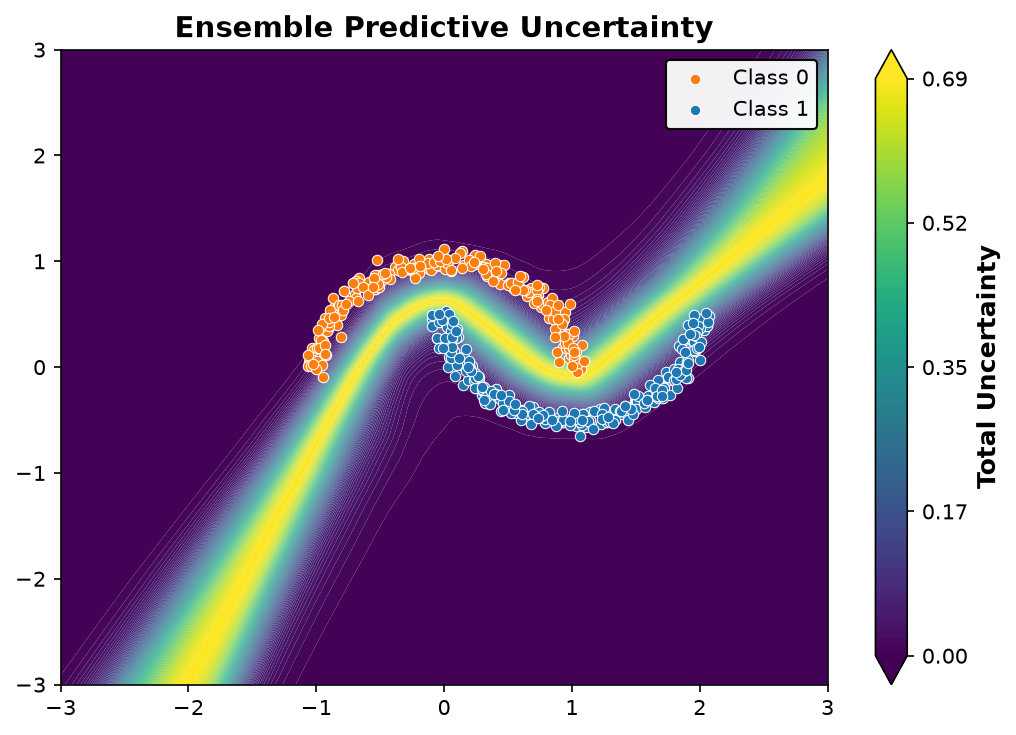

In [8]:
# Evaluates rep on a 200 x 200 grid and colors the input space by total uncertainty
plot = plot_example_uncertainty(X, y, rep, title="Ensemble Predictive Uncertainty", notion="total")
plot.show()

### 2h: Aleatoric and epistemic uncertainty

Plot both components of the decomposition separately.

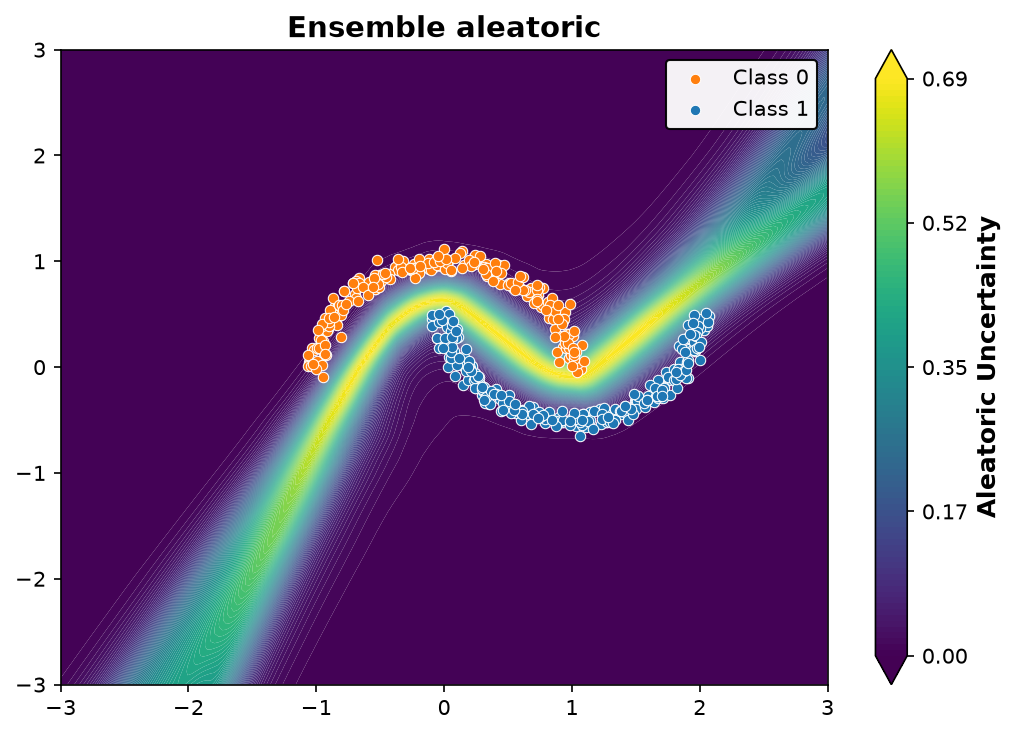

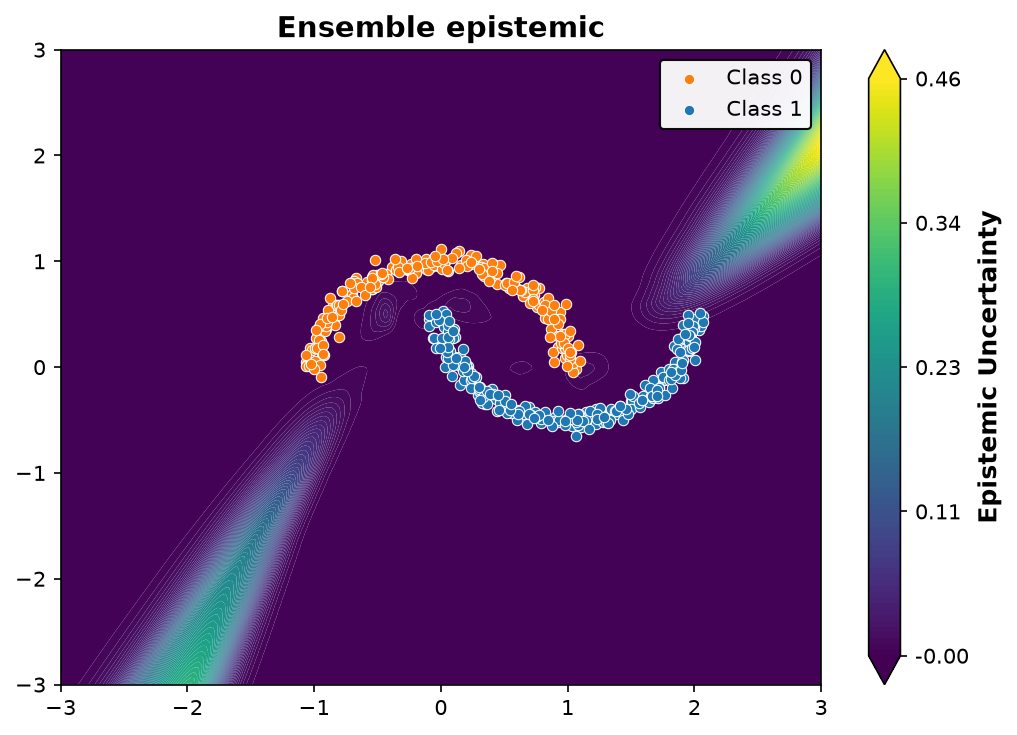

In [9]:
# Aleatoric: expected entropy of the members; epistemic: disagreement between them (total minus aleatoric)
for notion in ["aleatoric", "epistemic"]:
    plot = plot_example_uncertainty(X, y, rep, title=f"Ensemble {notion}", notion=notion)
    plot.show()

## Step 3: API check

### 3a: Quantify ensemble predictions

Inspect the decomposition for two training points; without `torch.no_grad()`, its tensors still show `grad_fn`.

In [10]:
from probly.quantification import quantify

# represent() builds the sample of member predictions, quantify() turns it into an entropy decomposition
decomp = quantify(rep.represent(X_tensor[:2]))  # first 2 training points

print(type(decomp).__name__)
print([a for a in dir(decomp) if not a.startswith("_")])
print("TU", decomp.total)
print("AU", decomp.aleatoric)
print("EU", decomp.epistemic)

SecondOrderEntropyDecomposition
['aleatoric', 'base', 'canonical_notion', 'components', 'distribution', 'epistemic', 'get', 'get_canonical', 'get_notion', 'items', 'keys', 'total', 'values']
TU tensor([0.0302, 0.3191], grad_fn=<AddBackward0>)
AU tensor([0.0299, 0.3109], grad_fn=<MeanBackward1>)
EU tensor([0.0003, 0.0082], grad_fn=<SubBackward0>)


### 3b: Quantify a manual sample

Run `quantify` on known probabilities so that the result can be checked independently.

In [11]:
import numpy as np

from probly.representation.distribution.numpy_categorical import (
    NumpyCategoricalDistributionSample,
    NumpyProbabilityCategoricalDistribution,
)

# shape (members, points, classes) = (3, 2, 3), same numbers as in probly's own test
probabilities = np.array(
    [
        [[0.70, 0.20, 0.10], [0.15, 0.35, 0.50]],
        [[0.60, 0.30, 0.10], [0.20, 0.30, 0.50]],
        [[0.80, 0.10, 0.10], [0.10, 0.40, 0.50]],
    ]
)
# Wraps plain probabilities in the type quantify() dispatches on; sample_axis=0 marks axis 0 as the members
sample = NumpyCategoricalDistributionSample(
    array=NumpyProbabilityCategoricalDistribution(probabilities),
    sample_axis=0,
)

check = quantify(sample)
print(type(check).__name__)
print("probly  TU", check.total, "AU", check.aleatoric, "EU", check.epistemic)

SecondOrderEntropyDecomposition
probly  TU [0.80181855 0.99857933] AU [0.77959871 0.99052691] EU [0.02221984 0.00805242]


### 3c: Check by hand

Recompute TU, AU and EU with plain NumPy and compare them with the output of 3b.

In [ ]:
# hand computation for comparison (natural log)
def entropy(p: np.ndarray) -> np.ndarray:
    return -(p * np.log(p)).sum(axis=-1)


# TU: entropy of the mean prediction; AU: mean entropy of the members; EU: the difference
tu = entropy(probabilities.mean(axis=0))
au = entropy(probabilities).mean(axis=0)
print("by hand TU", tu, "AU", au, "EU", tu - au)

by hand TU [0.80181855 0.99857933] AU [0.77959871 0.99052691] EU [0.02221984 0.00805242]


## Step 4: MC Dropout

### 4a: Base model

Create and print a fresh MLP as the starting point for dropout.

In [12]:
from probly.transformation import dropout

dropout_base = MLPClassifier()
print(dropout_base)  # architecture before the transformation, for comparison with 4b

MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


### 4b: Dropout transformation

Insert dropout layers; the shared mask makes each forward pass one coherent sub-network, similar to one ensemble member.

In [13]:
# Returns a modified copy with a dropout layer before every Linear layer except the first (see printout)
dropout_model = dropout(
    dropout_base,
    p=0.5,  # zeroing probability (kept active at inference)
    predictor_type="logit_classifier",
    shared_mask=True,  # one mask per forward pass, shared across the batch
)
print(dropout_model)

MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2_0): SharedMaskDropout(p=0.5)
    (2_1): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4_0): SharedMaskDropout(p=0.5)
    (4_1): Linear(in_features=64, out_features=2, bias=True)
  )
)


### 4c: Training

Train the single dropout model with its masks active.

In [14]:
# Only one model and one optimizer here, unlike the per-member loop in 2e
opt = torch.optim.Adam(dropout_model.parameters(), lr=1e-3)

dropout_model.train()  # needed here: dropout layers only draw masks in training mode
for epoch in range(300):
    opt.zero_grad()
    out = dropout_model(X_tensor)
    loss = nn.functional.cross_entropy(out, y_tensor)
    loss.backward()
    opt.step()

### 4d: Representer and plots

Draw 400 stochastic forward passes per input and plot all three uncertainty notions.

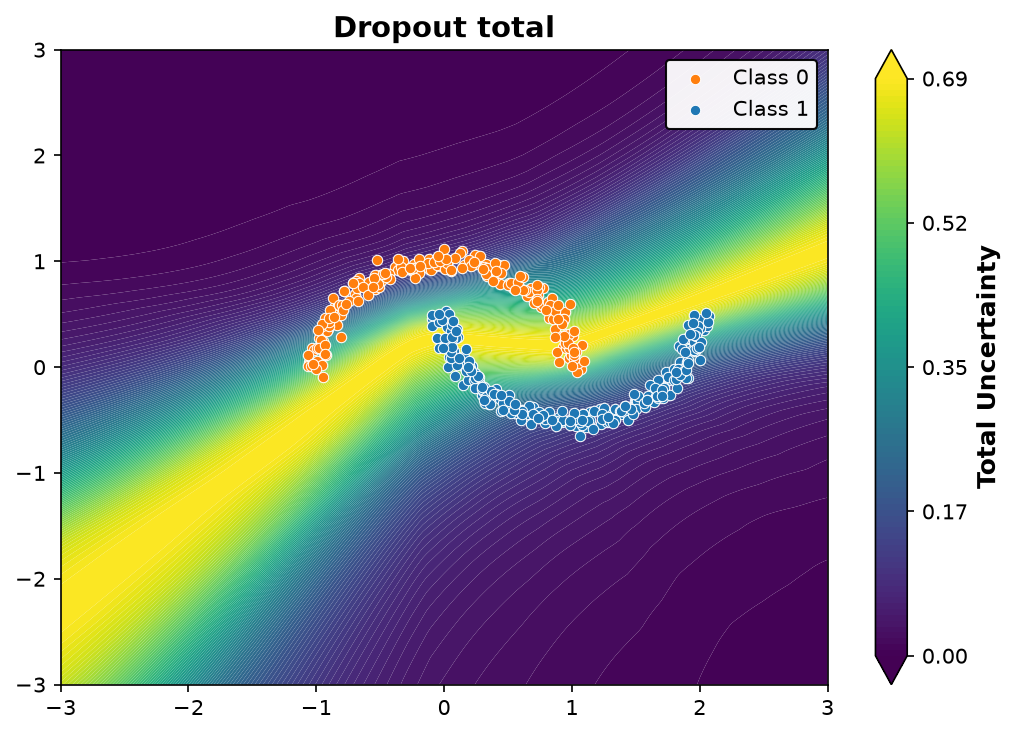

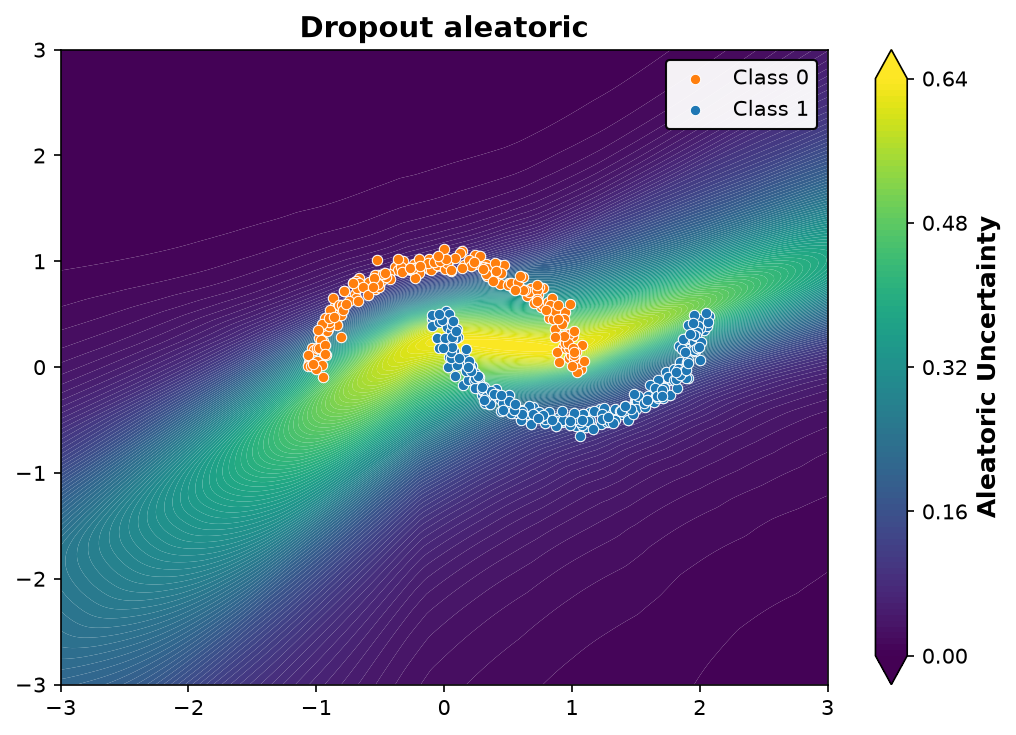

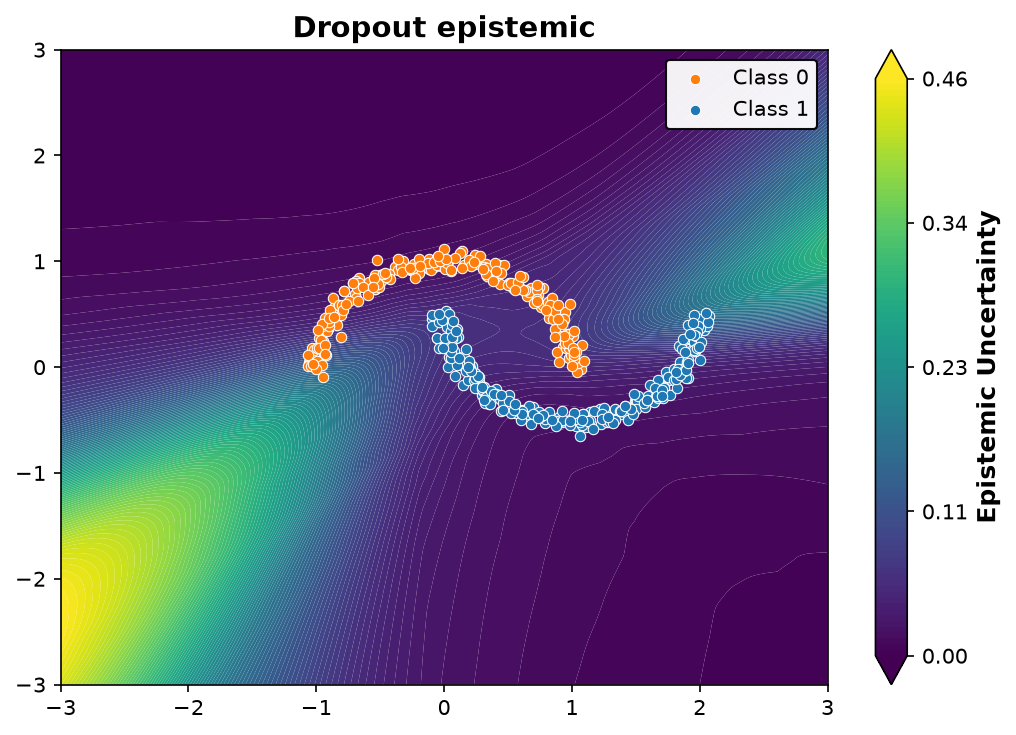

In [15]:
dropout_model.eval()
# The returned sampler switches dropout back on during represent() and restores eval mode afterwards
dropout_rep = representer(dropout_model, num_samples=400)

for notion in ["total", "aleatoric", "epistemic"]:
    plot = plot_example_uncertainty(X, y, dropout_rep, title=f"Dropout {notion}", notion=notion)
    plot.show()

## Step 5: Variations

### 5a: Helper functions

Wrap the ensemble recipe from Step 2 and its plots so that each variation stays short.

In [16]:
# Same steps as 2d-2f, with data, member count and epochs as parameters
def train_ensemble_rep(X_np, y_np, num_members=3, epochs=250, seed=0):
    """Train a probly deep ensemble on (X_np, y_np) and return its representer."""
    torch.manual_seed(seed)  # same seed -> same result on every run
    X_t = torch.from_numpy(X_np).float()
    y_t = torch.from_numpy(y_np).long()
    model = ensemble(
        MLPClassifier(),
        num_members=num_members,
        reset_params=True,
        predictor_type="logit_classifier",
    )
    model.train()
    for member in model:
        opt = torch.optim.Adam(member.parameters(), lr=1e-3)
        for _ in range(epochs):
            opt.zero_grad()
            loss = nn.functional.cross_entropy(member(X_t), y_t)
            loss.backward()
            opt.step()
    model.eval()
    return representer(model)


def show_au_eu(X_np, y_np, rep_v, label):
    """Plot aleatoric and epistemic uncertainty for one setting."""
    for notion in ["aleatoric", "epistemic"]:
        plot_example_uncertainty(X_np, y_np, rep_v, title=f"{label}: {notion}", notion=notion).show()

### 5b: More noise

Retrain on a dataset with `noise=0.3`.

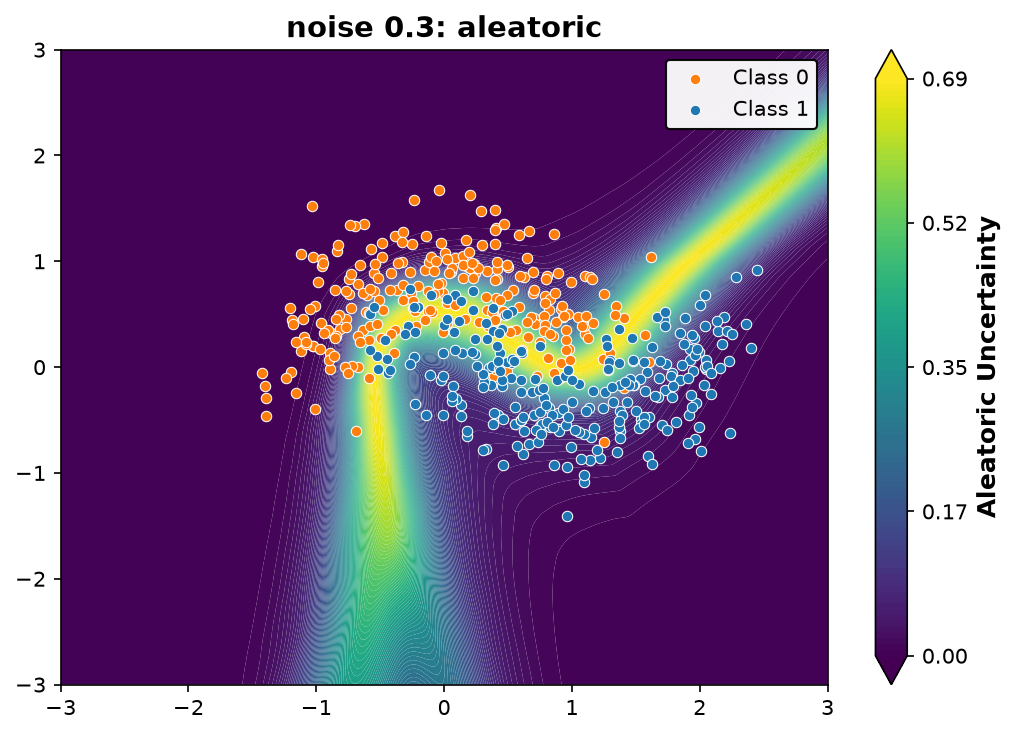

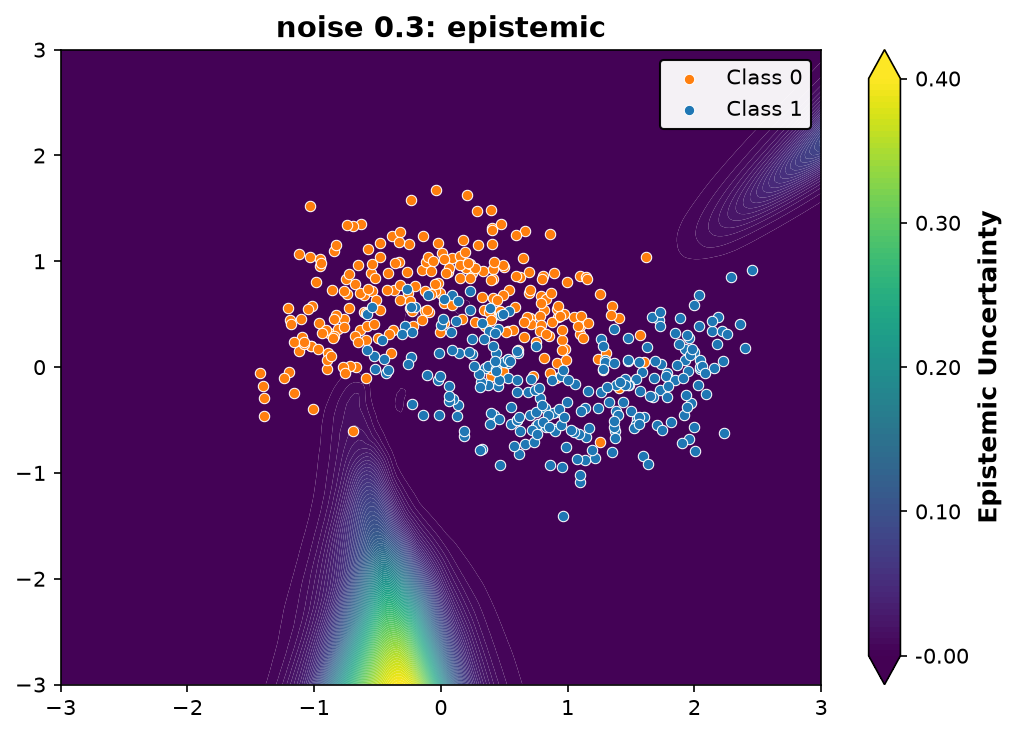

In [17]:
# Same size as in 2a, but the higher noise makes the classes overlap
X_noisy, y_noisy = make_moons(n_samples=500, noise=0.3, random_state=0)
show_au_eu(X_noisy, y_noisy, train_ensemble_rep(X_noisy, y_noisy), "noise 0.3")

### 5c: Fewer points

Retrain on only 50 points.

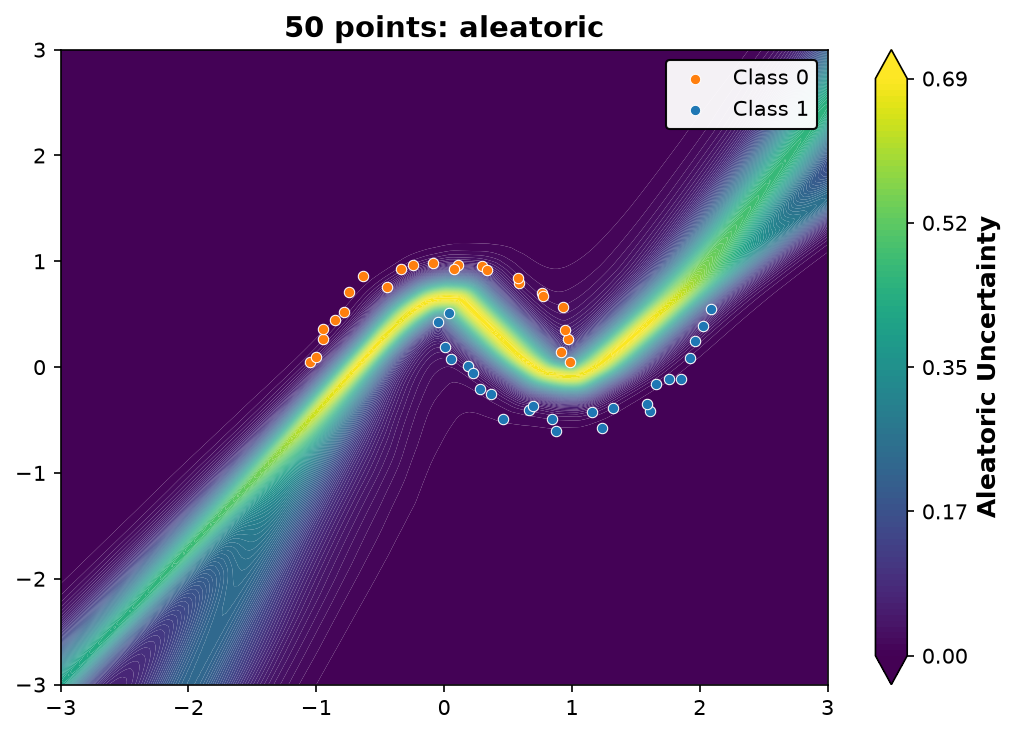

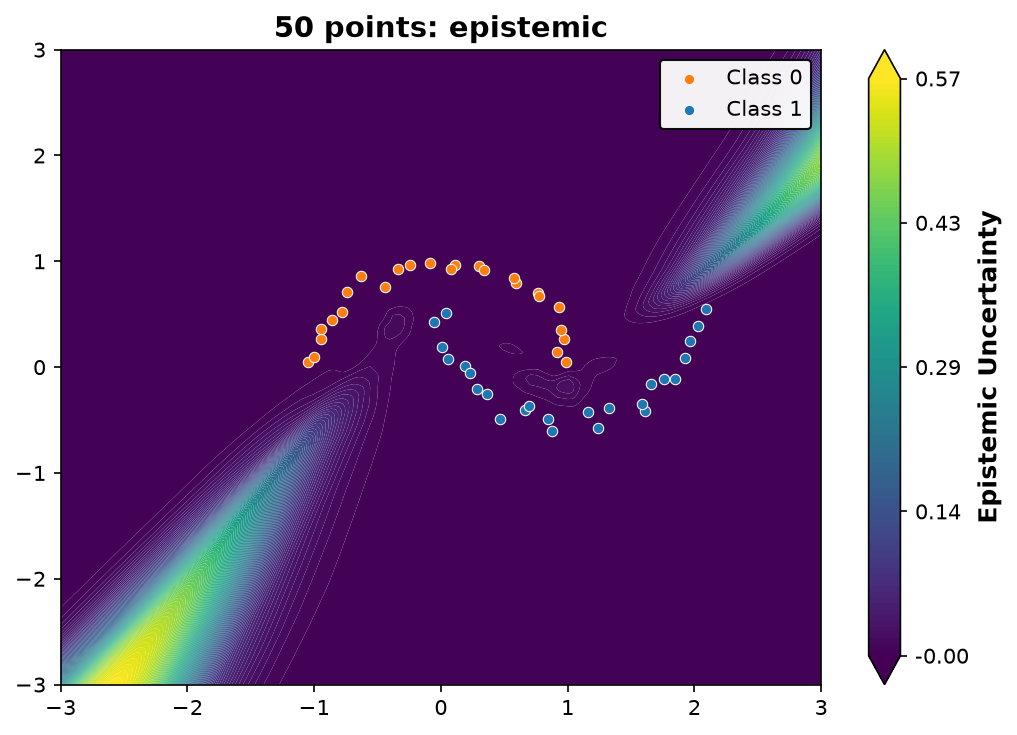

In [18]:
# Same noise as in 2a, but a tenth of the data
X_few, y_few = make_moons(n_samples=50, noise=0.05, random_state=0)
show_au_eu(X_few, y_few, train_ensemble_rep(X_few, y_few), "50 points")

### 5d: More members

Retrain on the original data with 10 instead of 3 members.

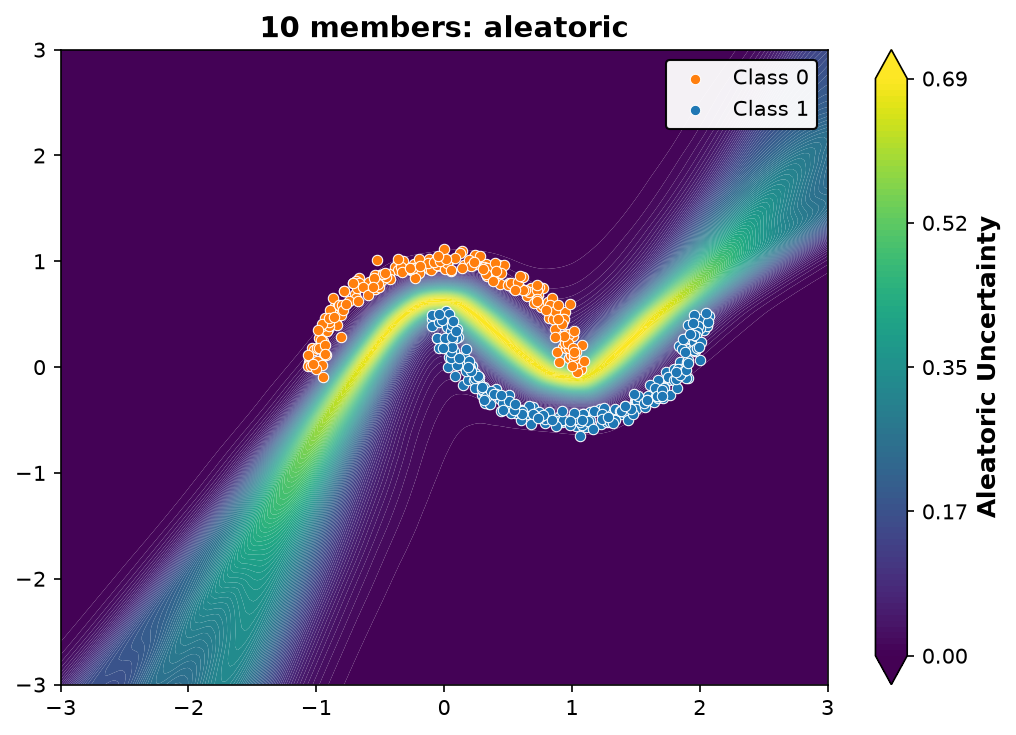

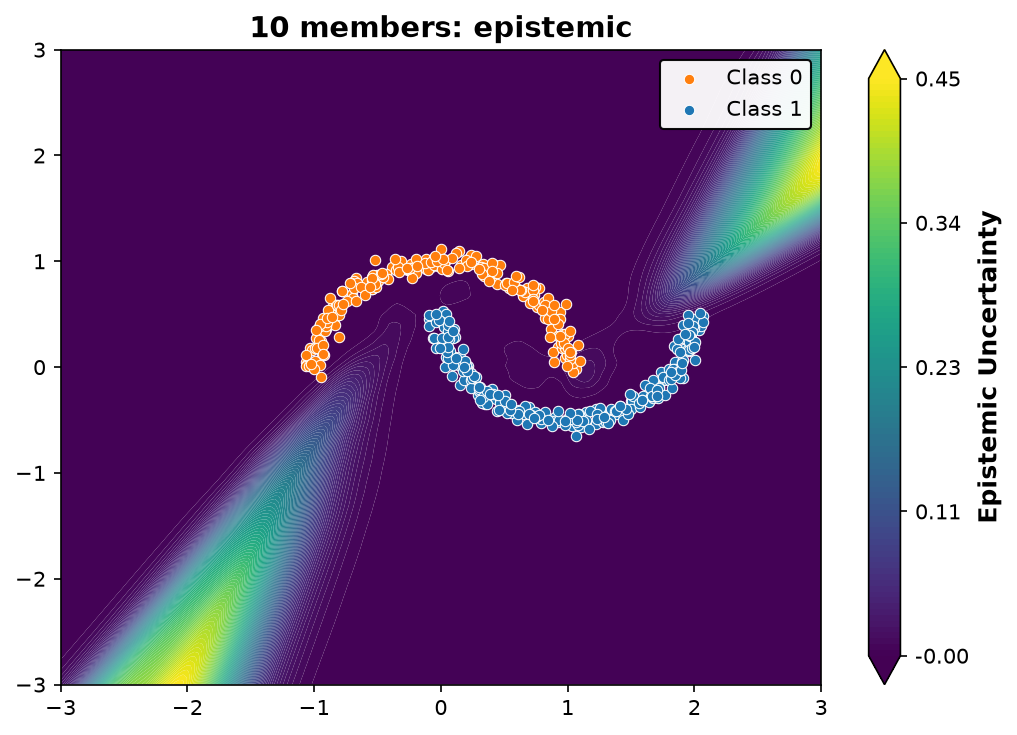

In [19]:
# Original data from 2a; only the number of members changes
show_au_eu(X, y, train_ensemble_rep(X, y, num_members=10), "10 members")

### 5e: Selected points

Compare AU and EU of the ensemble from Step 2 at four points outside the training data.

In [20]:
points = torch.tensor([[-2.5, 2.5], [2.6, 2.1], [2.5, -2.5], [-2.5, -2.5]])

with torch.no_grad():  # no gradient tracking -> plain numbers, no grad_fn
    d = quantify(rep.represent(points))  # rep from 2f, not one of the variations

print("points: top left, point 3 (top right), bottom right, bottom left")
print("AU", d.aleatoric.numpy().round(3))  # .numpy() would fail on tensors that still require gradients
print("EU", d.epistemic.numpy().round(3))

points: top left, point 3 (top right), bottom right, bottom left
AU [0.    0.212 0.    0.044]
EU [0.    0.109 0.    0.009]


### Observations

-
-
-

## Step 6: Attribution with shapiq

### 6a: Game definition

Define a game whose players are the features and whose value is the uncertainty at `x` when only some features are known.

In [26]:
def ensemble_member_probs(model, rows: np.ndarray) -> np.ndarray:
    """Return class probabilities of every ensemble member, shape (members, rows, classes)."""
    rows_t = torch.from_numpy(rows).float()
    with torch.no_grad():  # inference only, and .numpy() requires tensors without gradients
        return np.stack([torch.softmax(member(rows_t), dim=-1).numpy() for member in model])


def decompose_member_probs(probs: np.ndarray):
    """Quantify a (members, classes) array with probly's entropy decomposition."""
    # Same wrapping as in 3b, because these probabilities come from NumPy rather than from a representer
    sample = NumpyCategoricalDistributionSample(
        array=NumpyProbabilityCategoricalDistribution(probs[:, None, :]),  # add a point axis
        sample_axis=0,
    )
    return quantify(sample)


class ProblyUncertaintyGame(shapiq.Game):
    """Value of a coalition = uncertainty of a probly ensemble at x if only those features are known.

    Unknown features are filled with background rows (marginal imputation).
    order="mean_first": average each member's prediction over the background, then decompose.
    order="quantify_first": decompose each imputed row, then average the uncertainties.
    """

    def __init__(self, model, x: np.ndarray, background: np.ndarray, measure: str, order: str, rep=None) -> None:
        # A ready-made rep is needed for dropout, because representer(model) alone lacks num_samples
        self.model, self.rep = model, rep if rep is not None else representer(model)
        self.x, self.background = x, background
        self.measure, self.order = measure, order  # measure: "total", "aleatoric" or "epistemic"
        # One player per feature; normalize=False keeps the raw uncertainty as v(empty) instead of shifting it to 0
        super().__init__(n_players=x.shape[0], normalize=False)

    def value_function(self, coalitions: np.ndarray) -> np.ndarray:
        values = []
        for coalition in coalitions:  # boolean mask, True = feature known
            # Imputation: one row per background point, with the known features overwritten by their value at x
            rows = self.background.copy()  # copy so that the shared background stays unchanged
            rows[:, coalition] = self.x[coalition]  # unknown features keep background values
            if self.order == "mean_first":
                # Average over rows first, (members, rows, classes) -> (members, classes), then decompose one point
                decomp = decompose_member_probs(ensemble_member_probs(self.model, rows).mean(axis=1))
                values.append(float(getattr(decomp, self.measure)[0]))
            else:
                # quantify_first: decompose every imputed row on its own, then average the uncertainties over rows
                with torch.no_grad():  # .numpy() below requires tensors without gradients
                    decomp = quantify(self.rep.represent(torch.from_numpy(rows).float()))
                values.append(float(getattr(decomp, self.measure).numpy().mean()))
        return np.array(values)

### 6b: Both orders + efficiency check

Compute Shapley values for two points in both orders and check that they sum to `v(both) - v(empty)`; the orders can differ because entropy is not linear.

In [22]:
# All coalitions of the two features, in the order empty, x1, x2, both
coalitions = np.array([[False, False], [True, False], [False, True], [True, True]])

# (2.6, 2.1) lies outside the training data, (0.5, 0.25) between the two moons
for x_point in [np.array([2.6, 2.1]), np.array([0.5, 0.25])]:
    for order in ["mean_first", "quantify_first"]:
        print(f"\n=== x = {x_point}, order = {order} ===")
        for measure in ["aleatoric", "epistemic"]:
            game = ProblyUncertaintyGame(ensemble_model, x_point, X, measure, order)
            v = game.value_function(coalitions)
            # Exact Shapley values, feasible because two players only give four coalitions
            sv = shapiq.ExactComputer(game)(index="SV", order=1).dict_values
            phi = [sv[(0,)], sv[(1,)]]
            print(
                f"{measure:9s} v(empty, x1, x2, both) = {np.round(v, 3)}  "
                f"SV x1 = {phi[0]:+.3f}, x2 = {phi[1]:+.3f}  "
                f"check: sum = {sum(phi):+.3f} vs v(both) - v(empty) = {v[3] - v[0]:+.3f}"
            )


=== x = [2.6 2.1], order = mean_first ===
aleatoric v(empty, x1, x2, both) = [0.693 0.052 0.001 0.212]  SV x1 = -0.215, x2 = -0.266  check: sum = -0.481 vs v(both) - v(empty) = -0.481
epistemic v(empty, x1, x2, both) = [0.    0.005 0.    0.109]  SV x1 = +0.057, x2 = +0.052  check: sum = +0.109 vs v(both) - v(empty) = +0.109

=== x = [2.6 2.1], order = quantify_first ===
aleatoric v(empty, x1, x2, both) = [0.059 0.036 0.001 0.212]  SV x1 = +0.094, x2 = +0.059  check: sum = +0.153 vs v(both) - v(empty) = +0.153
epistemic v(empty, x1, x2, both) = [0.001 0.006 0.    0.109]  SV x1 = +0.057, x2 = +0.051  check: sum = +0.108 vs v(both) - v(empty) = +0.108

=== x = [0.5  0.25], order = mean_first ===
aleatoric v(empty, x1, x2, both) = [0.693 0.693 0.693 0.689]  SV x1 = -0.002, x2 = -0.002  check: sum = -0.004 vs v(both) - v(empty) = -0.004
epistemic v(empty, x1, x2, both) = [0.    0.    0.    0.001]  SV x1 = +0.001, x2 = +0.001  check: sum = +0.001 vs v(both) - v(empty) = +0.001

=== x = [0.5

### 6c: k-SII interaction

Compute k-SII values up to order 2 to separate the interaction of both features from their individual effects at (2.6, 2.1).

In [24]:
game = ProblyUncertaintyGame(ensemble_model, np.array([2.6, 2.1]), X, "epistemic", "quantify_first")
# Keys: () = baseline v(empty), (0,) and (1,) = single features, (0, 1) = pair interaction
print(shapiq.ExactComputer(game)(index="k-SII", order=2).dict_values)

{(): 0.0007882470963522792, (0, 1): 0.10399591691748356, (0,): 0.004763607052154839, (1,): -0.000727213471691357}


### 6d: Ensemble vs. dropout

Compare the Shapley values of both models at (2.6, 2.1) in the order `quantify_first`.

In [27]:
x_point = np.array([2.6, 2.1])
for measure in ["aleatoric", "epistemic"]:
    # Only quantify_first: mean_first iterates over members, and dropout_model has none
    for name, model, model_rep in [("ensemble", ensemble_model, rep), ("dropout", dropout_model, dropout_rep)]:
        game = ProblyUncertaintyGame(model, x_point, X, measure, "quantify_first", rep=model_rep)
        sv = shapiq.ExactComputer(game)(index="SV", order=1).dict_values
        print(f"{measure:9s} {name:8s} SV x1 = {sv[(0,)]:+.3f}, x2 = {sv[(1,)]:+.3f}")

aleatoric ensemble SV x1 = +0.094, x2 = +0.059
aleatoric dropout  SV x1 = +0.011, x2 = -0.174
epistemic ensemble SV x1 = +0.057, x2 = +0.051
epistemic dropout  SV x1 = +0.081, x2 = -0.025


### Observations

-
-
-